# TP 2.2 — Wasserstein GAN with Gradient Penalty (WGAN-GP)
**Introduction to Deep Generative Models **

**Group instructions:** Work in groups of two or three. Create a private GitHub repository, add **arthur-75**.

> All exercise placeholders (`xxx`) and unfinished tasks are intentionally retained. Complete the notebook yourself. Cells containing placeholders are not expected to execute until completed.

## 1. Introduction: Why WGAN-GP?

- WGAN (Wasserstein GAN) addresses mode collapse and training instability often encountered in standard GANs. It uses the **Wasserstein distance** (Earth Mover's Distance), rather than Jensen–Shannon divergence.
- **Gradient Penalty (GP)** further stabilizes training by encouraging the critic's gradient norm to be close to 1 at points interpolated between real and fake samples.

**Key concepts**

1. A **critic**, rather than a conventional discriminator, produces a real-valued score, not a probability.
2. **Wasserstein loss**: maximize critic scores for real samples relative to fake samples.
3. **Gradient penalty**: for interpolated samples $\hat{x}$, penalize deviations of $\|\nabla_{\hat{x}} D(\hat{x})\|_2$ from 1.

Review the corresponding Wasserstein and GP equations from the lecture.

## 2. Prepare the Data (CelebA)

1. Download/unzip CelebA.
2. Resize images to **64×64**.
3. Normalize pixel values to **[−1,+1]**.

Complete the unfinished data pipeline below.

In [24]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# -----------------------------
# 0. HYPERPARAMETERS
# -----------------------------
IMAGE_SIZE = 64
CHANNELS = 3
BATCH_SIZE = 128
Z_DIM = 128
LEARNING_RATE = 0.0002
BETA1 = 0.5
BETA2 = 0.999
EPOCHS = 2
CRITIC_STEPS = 5
GP_WEIGHT = 10.0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
!unzip -o /content/img_align_celeba.zip -d /content/img_align_celeba

Archive:  /content/img_align_celeba.zip
   creating: /content/img_align_celeba/img_align_celeba/
  inflating: /content/img_align_celeba/img_align_celeba/000001.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000002.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000003.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000004.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000005.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000006.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000007.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000008.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000009.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000010.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000011.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000012.jpg  
  inflating: /content/img_align_celeba/img_align_celeba/000013.jpg  
  infl

In [3]:
# -----------------------------
# 1. DATASET & DATALOADER
# -----------------------------
# Assumes CelebA images in a folder (adapt the structure as needed).
DATA_PATH = "/content/img_align_celeba"  # TODO: set your path

# TODO: complete the transforms (resize, tensor, normalize)
transform = transforms.Compose([
    transforms.Resize((64,64)),  # Pad 28x28 images to 32x32
    transforms.ToTensor(),# Convert images to tensors
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # Normalize
])


dataset = torchvision.datasets.ImageFolder(root=DATA_PATH, transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

## 3. Define the Critic

- Input: 64×64 RGB image (PyTorch shape `(3,64,64)`).
- Convolution layers downsample it to a single real-valued **score**.
- **No Sigmoid** at the output.

**Questions**

- Why remove the final Sigmoid in WGAN?
- How do dropout and stride-based downsampling influence training stability?

- Car on ne veut pas des valeurs très proche de 1 ou 0
- Ils le rendent plus stable.

In [4]:
# -----------------------------
# CRITIC (similar to discriminator)
# -----------------------------
class Critic(nn.Module):
    """Critic outputs one real-valued scalar score per image (no Sigmoid)."""
    def __init__(self, channels=3, features_d=64):
        super(Critic, self).__init__()
        self.model = nn.Sequential(
            # (channels, 64, 64) -> (features_d, 32, 32)
            nn.Conv2d(channels, features_d, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (features_d*2, 16, 16)
            nn.Conv2d(features_d, features_d*2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_d*2),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (features_d*4, 8, 8)
            nn.Conv2d(features_d*2, features_d*4, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_d*4),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (features_d*8, 4, 4)
            nn.Conv2d(features_d*4, features_d*8, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_d*8),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (1,1,1)
            nn.Conv2d(features_d*8, 1, kernel_size=4, stride=1, padding=0),
            nn.Flatten(start_dim=1),  # (batch_size, 1)
        )

    def forward(self, x):
        return self.model(x)

## 4. Define the Generator

- Input: latent vector $z\in\mathbb{R}^{Z\_DIM}$, reshaped as `(Z_DIM,1,1)`.
- Transposed convolutions upsample the latent representation.
- Output: RGB image `(3,64,64)`, usually with **Tanh** so values lie in **[−1,1]**.

In [20]:
# -----------------------------
# GENERATOR
# -----------------------------
class Generator(nn.Module):
    """Generator converts latent noise into 64x64 RGB images."""
    def __init__(self, z_dim=Z_DIM, channels=CHANNELS, features_g=64):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            # (z_dim, 1, 1) -> (features_g*8, 4, 4)
            nn.ConvTranspose2d(Z_DIM, features_g*8, kernel_size=4, stride=1, padding=0),
            nn.BatchNorm2d(features_g*8),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (features_g*4, 8, 8)
            nn.ConvTranspose2d(features_g*8, features_g*4, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_g*4),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (features_g*2, 16, 16)
            nn.ConvTranspose2d(features_g*4, features_g*2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_g*2),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (features_g, 32, 32)
            nn.ConvTranspose2d(features_g*2, features_g, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_g),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (channels, 64, 64)
            nn.ConvTranspose2d(features_g, CHANNELS, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        return self.model(x)

### Initialize models and optimizers

Complete the model construction and optimizer definitions.

In [21]:
critic = Critic(channels=CHANNELS, features_d=IMAGE_SIZE).to(DEVICE)
generator = Generator(z_dim=Z_DIM, channels=CHANNELS, features_g=IMAGE_SIZE).to(DEVICE)

# WGAN-GP: Adam optimizers
critic_optimizer = optim.Adam(critic.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
generator_optimizer = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

## 6. Gradient Penalty (GP)

1. Sample $\alpha\in[0,1]$.
2. Interpolate between a real image and a generated image.
3. Compute the gradient of the critic's output with respect to that interpolation.
4. Penalize deviations of the gradient's $L_2$ norm from 1.

**Questions**

- Why does WGAN-GP interpolate between real and fake samples?
- What if the gradient norm is zero or extremely large?

- C'est pour eviter que le discriminateur puissent faire trop facilement la différence entre vrai et fausse images
- Si elle est trop proche de 0 le discrimanateur n'arrive à différencier le faux du vrai et si elle est trop proche de 1 il ne se trompe jamais.

In [22]:
# -----------------------------
# GRADIENT PENALTY (starter code from the exercise)
# -----------------------------
def gradient_penalty(critic, real, fake, device="cpu"):
    """Calculate penalty from critic gradients on interpolated inputs."""
    batch_size, c, h, w = real.shape
    alpha = torch.rand((batch_size, 1, 1, 1), device=device).repeat(1, c, h, w)

    interpolated = real * alpha + fake * (1 - alpha)
    interpolated.requires_grad_(True)
    mixed_scores = critic(interpolated)
    gradient = torch.autograd.grad(
        inputs=interpolated,
        outputs=mixed_scores,
        grad_outputs=torch.ones_like(mixed_scores),
        create_graph=True,
        retain_graph=True,
    )[0]
    gradient = gradient.view(gradient.size(0), -1)
    gradient_norm = gradient.norm(2, dim=1)
    gp = torch.mean((gradient_norm - 1) ** 2)
    return gp

## 7. Compile and Train

- Critic loss: expected fake score − expected real score + weighted gradient penalty.
- Generator loss: negative expected fake score.
- Train the critic **CRITIC_STEPS** times per generator update.
- Save checkpoints and generate examples during training.

**Watch for:** NaN losses, incorrect gradient-penalty computations, unsuitable learning rates, or memory limitations.

The training code below is **starter code from the PDF**, not a corrected reference implementation.

In [25]:
print("Starting Training...")
g_losses = []
c_losses = []

for epoch in range(EPOCHS):
    progress_bar = tqdm(enumerate(dataloader), total=len(dataloader),
                        desc=f"Epoch {epoch+1}/{EPOCHS}")

    for batch_idx, (real_images, _) in progress_bar:
        real_images = real_images.to(DEVICE)
        cur_batch_size = real_images.shape[0]

        # (a) Train Critic multiple times
        for _ in range(CRITIC_STEPS):
            noise = torch.randn(cur_batch_size, Z_DIM, 1, 1, device=DEVICE)
            fake_images = generator(noise)
            critic_optimizer.zero_grad()

            critic_real = critic(real_images).view(-1)
            critic_fake = critic(fake_images).view(-1)
            wass_distance = torch.mean(critic_fake) - torch.mean(critic_real)
            gp = gradient_penalty(critic, real_images, fake_images, device=DEVICE)
            critic_loss = wass_distance + GP_WEIGHT * gp
            critic_loss.backward(retain_graph=True)
            critic_optimizer.step()

        # (b) Train Generator
        generator_optimizer.zero_grad()
        critic_fake_for_g = critic(fake_images).view(-1)
        gen_loss = -torch.mean(critic_fake_for_g)
        gen_loss.backward()
        generator_optimizer.step()

        c_losses.append(critic_loss.item())
        g_losses.append(gen_loss.item())
        progress_bar.set_postfix({
            "Critic Loss": f"{critic_loss.item():.4f}",
            "GP": f"{gp.item():.4f}",
            "WassDist": f"{wass_distance.item():.4f}",
            "Gen Loss": f"{gen_loss.item():.4f}",
        })

Starting Training...


Epoch 2/2: 100%|██████████| 26/26 [24:32<00:00, 56.63s/it, Critic Loss=-15.1059, GP=0.2651, WassDist=-17.7566, Gen Loss=199.8092]


### Optional: load pretrained models

If training does not work, you may use a pretrained generator and critic. Supply checkpoint paths yourself.

In [ ]:
# Load state dictionaries (supply GEN_PATH and CRITIC_PATH)
generator.load_state_dict(torch.load(GEN_PATH, map_location=DEVICE))
critic.load_state_dict(torch.load(CRITIC_PATH, map_location=DEVICE))
generator.eval()
critic.eval()

## 8. Plot Losses

Plot the recorded critic and generator losses across training iterations.

**Question:** What do you observe? C'est mieux.

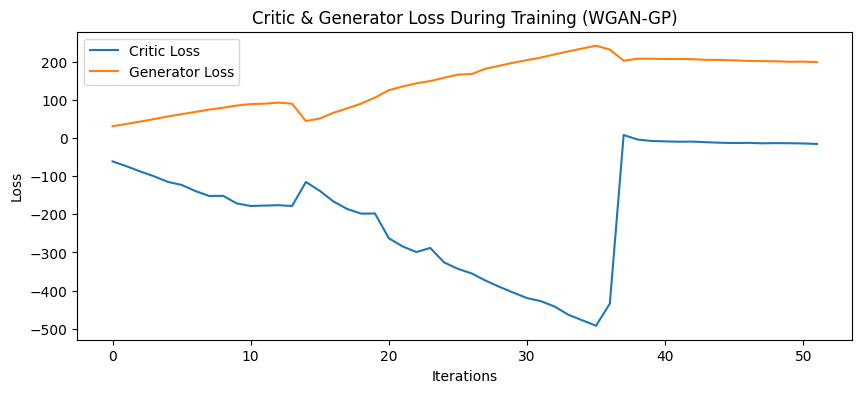

In [26]:
plt.figure(figsize=(10,4))
plt.title("Critic & Generator Loss During Training (WGAN-GP)")
plt.plot(c_losses, label="Critic Loss")
plt.plot(g_losses, label="Generator Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

## 9. Generate Images & Evaluate

1. Sample random latent vectors $z$.
2. Generate images $G(z)$.
3. Display or save the generated faces.

**Optional follow-up:** Modify `Z_DIM` or the number of convolutional layers; explore Fréchet Inception Distance (FID) or Inception Score.

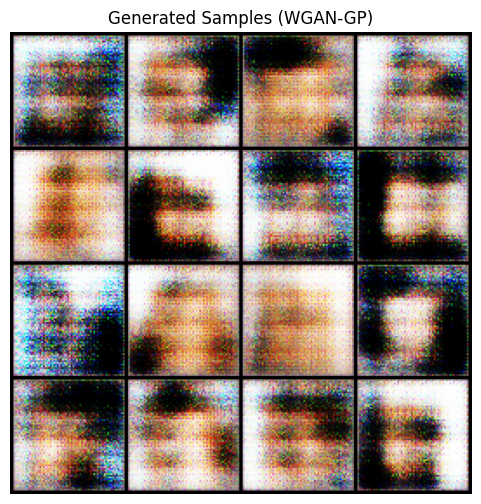

In [27]:
def show_generated_samples(generator, num_samples=16, z_dim=Z_DIM):
    """Generate samples and display them as a grid."""
    generator.eval()
    noise = torch.randn(num_samples, z_dim, 1, 1).to(DEVICE)
    with torch.no_grad():
        fake = generator(noise)
    fake = fake.cpu() * 0.5 + 0.5
    grid_img = torchvision.utils.make_grid(fake, nrow=4)
    plt.figure(figsize=(6,6))
    plt.imshow(grid_img.permute(1, 2, 0).numpy())
    plt.axis("off")
    plt.title("Generated Samples (WGAN-GP)")
    plt.show()
    generator.train()

show_generated_samples(generator, num_samples=16)